In [1]:
%pip install yfinance pandas numpy matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("seaborn-v0_8-whitegrid")

print("Libraries imported successfully.")
print("NumPy version:", np.__version__)
print("pandas version:", pd.__version__)

Libraries imported successfully.
NumPy version: 2.5.3
pandas version: 3.0.6


In [3]:
tickers = ["MSFT", "^GSPC"]

data = yf.download(
    tickers,
    period="3y",
    interval="1d",
    auto_adjust=True,
    progress=False
)

if data.empty:
    raise ValueError(
        "No data downloaded. Check your internet connection."
    )

prices = data["Close"].copy()

prices = prices.rename(columns={
    "MSFT": "Microsoft",
    "^GSPC": "SP500"
})

prices.index = pd.to_datetime(prices.index)

if prices.index.tz is not None:
    prices.index = prices.index.tz_localize(None)

prices = prices.sort_index()
prices = prices[~prices.index.duplicated(keep="first")]

print("Dataset dimensions:", prices.shape)
print("\nFirst five observations:")
display(prices.head())

print("\nLast five observations:")
display(prices.tail())

Dataset dimensions: (751, 2)

First five observations:


Ticker,Microsoft,SP500
Date,,
2023-10-30,329.590454,4166.819824
2023-10-31,330.372162,4193.799805
2023-11-01,338.149963,4237.859863
2023-11-02,340.348480,4317.779785
2023-11-03,344.725952,4358.339844



Last five observations:


Ticker,Microsoft,SP500
Date,,
2026-10-21,532.950012,7757.169922
2026-10-22,521.080017,7663.430176
2026-10-23,524.510010,7623.680176
2026-10-26,532.599976,7676.770020
2026-10-27,531.330017,7722.600098


In [4]:
print("Column data types:")
print(prices.dtypes)

print("\nMissing values:")
print(prices.isna().sum())

print("\nDuplicate dates:", prices.index.duplicated().sum())

print("\nSummary statistics:")
display(prices.describe())

Column data types:
Ticker
Microsoft    float64
SP500        float64
dtype: object

Missing values:
Ticker
Microsoft    0
SP500        0
dtype: int64

Duplicate dates: 0

Summary statistics:


Ticker,Microsoft,SP500
count,751.000000,751.000000
mean,432.255783,6150.656777
std,49.079492,915.358836
min,329.590454,4166.819824
25%,397.047577,5459.790039
50%,417.600555,6032.379883
75%,476.904434,6850.320068
max,543.450012,7818.930176


In [5]:
prices = prices.dropna()

assert not prices.empty, "The dataset is empty."
assert not prices.index.duplicated().any(), "Duplicate dates found."
assert (prices > 0).all().all(), "Nonpositive prices found."

print("Data validation passed.")
print("Observations available:", len(prices))
print("Start date:", prices.index.min().date())
print("End date:", prices.index.max().date())

Data validation passed.
Observations available: 751
Start date: 2023-10-30
End date: 2026-10-27


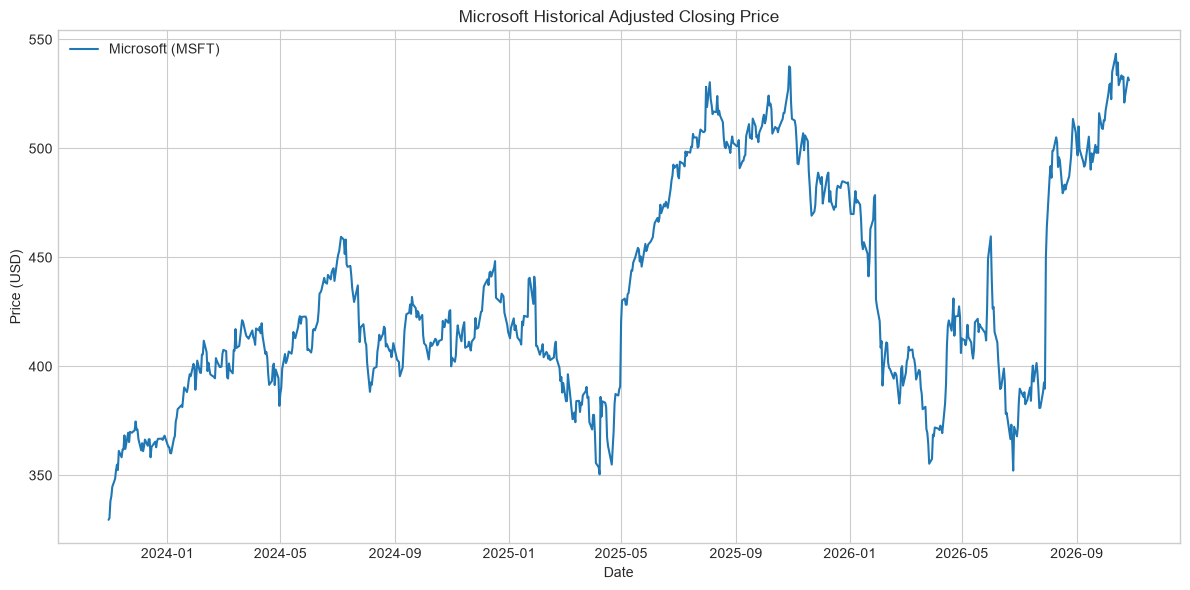

In [6]:
plt.figure(figsize=(12, 6))

plt.plot(
    prices.index,
    prices["Microsoft"],
    label="Microsoft (MSFT)"
)

plt.title("Microsoft Historical Adjusted Closing Price")
plt.xlabel("Date")
plt.ylabel("Price (USD)")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
# Calculate daily percentage returns
daily_returns = prices.pct_change(fill_method=None).dropna()

print("Daily returns calculated successfully.")
display(daily_returns.head())

Daily returns calculated successfully.


Ticker,Microsoft,SP500
Date,,
2023-10-31,0.002372,0.006475
2023-11-01,0.023543,0.010506
2023-11-02,0.006502,0.018859
2023-11-03,0.012862,0.009394
2023-11-06,0.010573,0.001753


In [8]:
# Calculate cumulative returns
cumulative_returns = (1 + daily_returns).cumprod() - 1

print("Latest cumulative returns:")
display(cumulative_returns.tail(1))

# Convert final cumulative returns to percentages
final_returns = cumulative_returns.iloc[-1] * 100

print(f"Microsoft cumulative return: {final_returns['Microsoft']:.2f}%")
print(f"S&P 500 cumulative return: {final_returns['SP500']:.2f}%")

Latest cumulative returns:


Ticker,Microsoft,SP500
Date,,
2026-10-27,0.612092,0.853356


Microsoft cumulative return: 61.21%
S&P 500 cumulative return: 85.34%


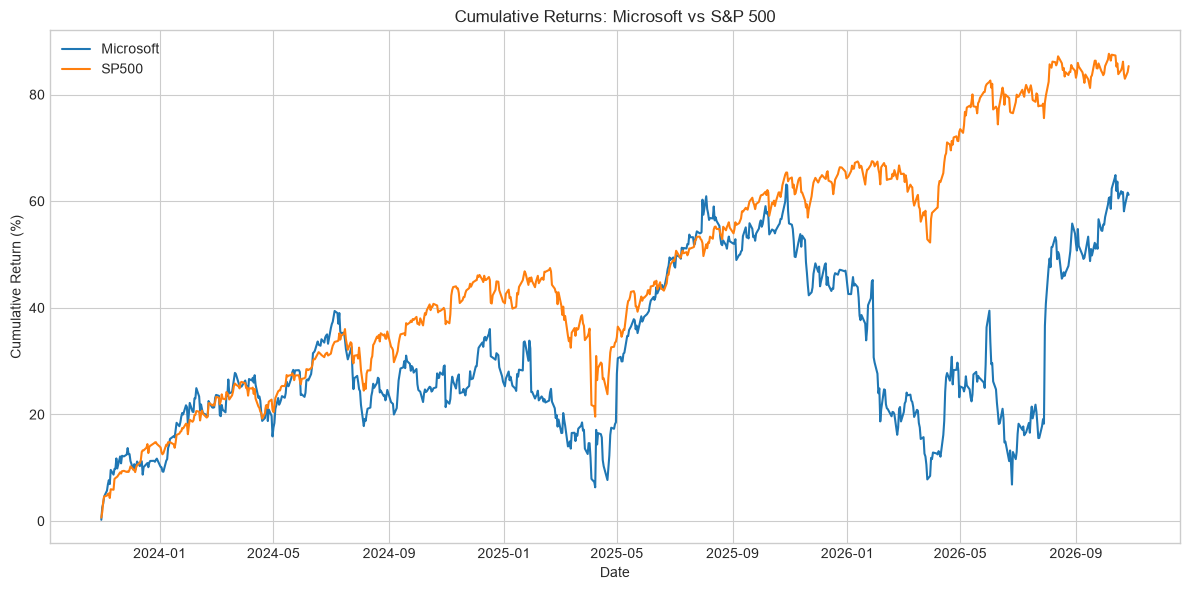

In [9]:
plt.figure(figsize=(12, 6))

for column in cumulative_returns.columns:
    plt.plot(
        cumulative_returns.index,
        cumulative_returns[column] * 100,
        label=column
    )

plt.title("Cumulative Returns: Microsoft vs S&P 500")
plt.xlabel("Date")
plt.ylabel("Cumulative Return (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [10]:
# Annualized volatility
annualized_volatility = daily_returns.std() * np.sqrt(252)

print("Annualized volatility:")
display((annualized_volatility * 100).round(2).astype(str) + "%")

Annualized volatility:


Ticker
Microsoft    26.15%
SP500        14.93%
dtype: str

In [11]:
# Build a hypothetical investment value index
wealth_index = (1 + daily_returns).cumprod()

# Track the running maximum
running_peak = wealth_index.cummax()

# Calculate drawdown from each peak
drawdown = (wealth_index / running_peak) - 1

# Most severe drawdown for each asset
max_drawdown = drawdown.min()

print("Maximum drawdown:")
display((max_drawdown * 100).round(2).astype(str) + "%")

Maximum drawdown:


Ticker
Microsoft    -34.5%
SP500        -18.9%
dtype: str

In [12]:
summary = pd.DataFrame({
    "Cumulative Return (%)": cumulative_returns.iloc[-1] * 100,
    "Annualized Volatility (%)": annualized_volatility * 100,
    "Maximum Drawdown (%)": max_drawdown * 100
})

summary = summary.round(2)

display(summary)

,Cumulative Return (%),Annualized Volatility (%),Maximum Drawdown (%)
Ticker,,,
Microsoft,61.21,26.15,-34.5
SP500,85.34,14.93,-18.9


In [13]:
# Calculate annualized Sharpe ratio, assuming a 0% risk-free rate
annualized_mean_return = daily_returns.mean() * 252
annualized_volatility = daily_returns.std() * np.sqrt(252)

sharpe_ratio = annualized_mean_return / annualized_volatility

print("Annualized Sharpe ratio:")
display(sharpe_ratio.round(3))

Annualized Sharpe ratio:


Ticker
Microsoft    0.743
SP500        1.464
dtype: float64

In [14]:
# Calculate annualized compounded return (CAGR)
years = (
    daily_returns.index[-1] - daily_returns.index[0]
).days / 365.25

annualized_cagr = (
    (1 + cumulative_returns.iloc[-1]) ** (1 / years) - 1
)

# Combine all performance and risk metrics
performance_summary = pd.DataFrame({
    "Cumulative Return (%)": cumulative_returns.iloc[-1] * 100,
    "Annualized CAGR (%)": annualized_cagr * 100,
    "Annualized Volatility (%)": annualized_volatility * 100,
    "Sharpe Ratio (0% risk-free)": sharpe_ratio,
    "Maximum Drawdown (%)": max_drawdown * 100
})

performance_summary = performance_summary.round(2)

display(performance_summary)

,Cumulative Return (%),Annualized CAGR (%),Annualized Volatility (%),Sharpe Ratio (0% risk-free),Maximum Drawdown (%)
Ticker,,,,,
Microsoft,61.21,17.32,26.15,0.74,-34.5
SP500,85.34,22.92,14.93,1.46,-18.9


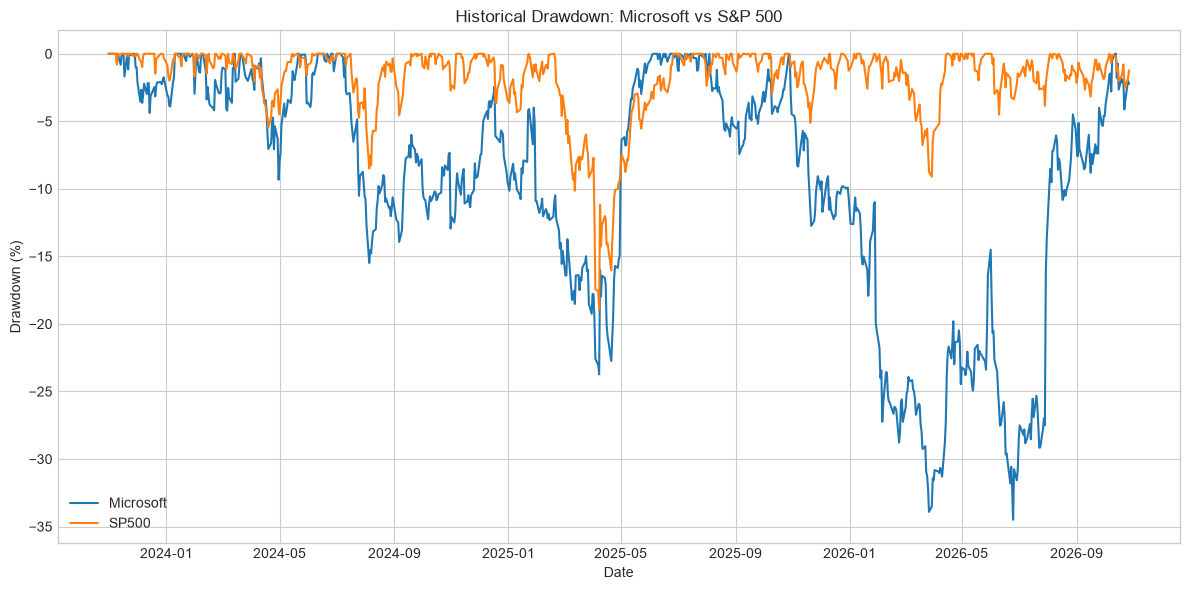

In [15]:
plt.figure(figsize=(12, 6))

for column in drawdown.columns:
    plt.plot(
        drawdown.index,
        drawdown[column] * 100,
        label=column
    )

plt.title("Historical Drawdown: Microsoft vs S&P 500")
plt.xlabel("Date")
plt.ylabel("Drawdown (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [16]:
# Save performance metrics
performance_summary.to_csv("msft_performance_summary.csv")

# Save daily returns
daily_returns.to_csv("msft_daily_returns.csv")

print("Files saved successfully:")
print("- msft_performance_summary.csv")
print("- msft_daily_returns.csv")

Files saved successfully:
- msft_performance_summary.csv
- msft_daily_returns.csv
